<a href="https://colab.research.google.com/github/nn250327/dl-unit-test/blob/main/language_identification_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import re
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



In [17]:
import zipfile
import os

# Unzip archive.zip to extract the CSV file
zip_path = "archive.zip"
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")
    print("Extracted files from archive.zip")

# Load the extracted CSV file (spam_sms.csv)
csv_file = "spam_sms.csv"
if os.path.exists(csv_file):
    df = pd.read_csv(csv_file, encoding="latin-1")
else:
    raise FileNotFoundError(f"Could not find {csv_file} after extraction.")

print("Original dataset shape:", df.shape)

# Display missing values
print("\nMissing values:")
print(df.isnull().sum())

Extracted files from archive.zip
Original dataset shape: (5572, 2)

Missing values:
v1    0
v2    0
dtype: int64


In [20]:
# Rename the columns to logical names
df = df.rename(columns={"v1": "label", "v2": "Text"})

# Drop missing values based on the correct columns
df = df.dropna(subset=["Text", "label"])

# Convert text to string
df["Text"] = df["Text"].astype(str)

# Remove duplicate records
df = df.drop_duplicates()

print("\nDataset after cleaning:", df.shape)


Dataset after cleaning: (5169, 2)


In [24]:
df = (
    df.groupby("label", group_keys=False)
      .apply(lambda x: x.sample(n=min(500, len(x)), random_state=42))
      .reset_index(drop=True)
)

print("\nSubset shape:", df.shape)

print("\nLabel distribution:")
print(df["label"].value_counts())


Subset shape: (1000, 4)

Label distribution:
label
ham     500
spam    500
Name: count, dtype: int64


/tmp/ipykernel_617/2251214461.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(500, len(x)), random_state=42))


In [26]:
def clean_text(text):
    text = text.lower()

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["Text"] = df["Text"].apply(clean_text)


In [30]:
classes = sorted(df["label"].unique())

label_to_id = {
    label: i
    for i, label in enumerate(classes)
}

id_to_label = {
    i: label
    for label, i in label_to_id.items()
}

df["label_id"] = df["label"].map(label_to_id)

print("\nNumber of classes:", len(classes))
print("Classes:", classes)


Number of classes: 2
Classes: ['ham', 'spam']


In [31]:
train_texts, test_texts, train_labels, test_labels = train_test_split(
    df["Text"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("\nTraining samples:", len(train_texts))
print("Testing samples:", len(test_texts))



Training samples: 800
Testing samples: 200


In [32]:
counter = Counter()

for text in train_texts:
    for word in text.split():
        counter[word] += 1


# Keep most common 20,000 words
MAX_VOCAB = 20000

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

print("\nVocabulary size:", len(vocab))


Vocabulary size: 4308


In [33]:
MAX_LENGTH = 50


def tokenize(text):
    words = text.split()

    sequence = []

    for word in words:
        if word in vocab:
            sequence.append(vocab[word])
        else:
            sequence.append(vocab["<UNK>"])

    # Truncate
    sequence = sequence[:MAX_LENGTH]

    # Padding
    while len(sequence) < MAX_LENGTH:
        sequence.append(vocab["<PAD>"])

    return sequence


X_train = [tokenize(text) for text in train_texts]
X_test = [tokenize(text) for text in test_texts]

In [36]:
class LanguageDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = torch.tensor(texts, dtype=torch.long)
        # Map string labels to numerical label IDs
        numerical_labels = [label_to_id[label] for label in labels]
        self.labels = torch.tensor(numerical_labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.texts[index], self.labels[index]


train_dataset = LanguageDataset(X_train, train_labels)
test_dataset = LanguageDataset(X_test, test_labels)


train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [37]:
class LSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        output, (hidden, cell) = self.lstm(x)

        # Take final hidden state
        hidden = hidden[-1]

        output = self.fc(hidden)

        return output

In [40]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nUsing device:", device)


model = LSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=64,
    hidden_dim=64,
    num_classes=len(classes)
)

model = model.to(device)


criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


Using device: cpu


In [43]:
EPOCHS = 5

print("\nTraining started...\n")

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for texts, labels in train_loader:

        texts = texts.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(texts)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Loss: {average_loss:.4f}"
    )


Training started...

Epoch 1/5 - Loss: 0.6894
Epoch 2/5 - Loss: 0.6888
Epoch 3/5 - Loss: 0.6878
Epoch 4/5 - Loss: 0.6877
Epoch 5/5 - Loss: 0.6877


In [44]:
model.eval()

actual = []
predicted = []

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(device)

        outputs = model(texts)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        actual.extend(labels.numpy())
        predicted.extend(predictions.cpu().numpy())


In [45]:
accuracy = accuracy_score(
    actual,
    predicted
)

precision = precision_score(
    actual,
    predicted,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    actual,
    predicted,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    actual,
    predicted,
    average="weighted",
    zero_division=0
)


print("\n-----------------------------")
print("MODEL EVALUATION")
print("-----------------------------")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")



-----------------------------
MODEL EVALUATION
-----------------------------
Accuracy  : 0.5150
Precision : 0.7538
Recall    : 0.5150
F1-Score  : 0.3658


In [47]:
def predict_spam(text):

    model.eval()

    text = clean_text(text)

    sequence = tokenize(text)

    tensor = torch.tensor(
        [sequence],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        output = model(tensor)

        prediction = torch.argmax(
            output,
            dim=1
        ).item()

    return id_to_label[prediction]


# Example
sample = "This is a simple English sentence."

print("\nInput:", sample)

print(
    "Predicted Label:",
    predict_spam(sample)
)


Input: This is a simple English sentence.
Predicted Label: spam


In [48]:
!pip install torch pandas scikit-learn

In [49]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [51]:
import pandas as pd
import re
import zipfile
import os

# Extract dataset.csv from the uploaded archive (2).zip first
zip_path = "archive (2).zip"
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extract("dataset.csv", ".")
    print("Successfully extracted dataset.csv from archive (2).zip")

df = pd.read_csv("dataset.csv")

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

# Remove missing values
df = df.dropna(subset=["Text", "language"])

# Convert text to string
df["Text"] = df["Text"].astype(str)

# Remove duplicates
df = df.drop_duplicates()

# Take 500 samples from each language
df = (
    df.groupby("language", group_keys=False)
      .apply(lambda x: x.sample(n=min(500, len(x)), random_state=42))
      .reset_index(drop=True)
)

print("\nSubset shape:", df.shape)

print("\nLanguage distribution:")
print(df["language"].value_counts())


# Text preprocessing
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


df["Text"] = df["Text"].apply(clean_text)

print("\nFirst 5 records:")
print(df.head())

Successfully extracted dataset.csv from archive (2).zip
Dataset shape: (22000, 2)

Missing values:
Text        0
language    0
dtype: int64

Subset shape: (11000, 2)

Language distribution:
language
Arabic        500
Chinese       500
Dutch         500
English       500
Estonian      500
French        500
Hindi         500
Indonesian    500
Japanese      500
Korean        500
Latin         500
Persian       500
Portugese     500
Pushto        500
Romanian      500
Russian       500
Spanish       500
Swedish       500
Tamil         500
Thai          500
Turkish       500
Urdu          500
Name: count, dtype: int64


/tmp/ipykernel_617/780526788.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(500, len(x)), random_state=42))



First 5 records:
                                                Text language
0  ولكن سيمور قامت بسحب قصتها لاحقا وتقدم رجل اخر...   Arabic
1  استمرت هذه الابادة حتى أنهاها القائمون على خدم...   Arabic
2  حمض البورونيك هو حمض مشتق من حمض البوريك وذلك ...   Arabic
3  قاموس ميريام وبستر إما الشيء الذي هو "من أو ال...   Arabic
4  وخلافا لتقارير الإعلام والجدال في ذلك الوقت ال...   Arabic


In [52]:
from collections import Counter
from sklearn.model_selection import train_test_split

# Encode languages
languages = sorted(df["language"].unique())

language_to_id = {
    language: i
    for i, language in enumerate(languages)
}

id_to_language = {
    i: language
    for language, i in language_to_id.items()
}

df["label"] = df["language"].map(language_to_id)

print("Number of languages:", len(languages))
print("Languages:", languages)


# Train-test split
train_texts, test_texts, train_labels, test_labels = train_test_split(
    df["Text"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training samples:", len(train_texts))
print("Testing samples:", len(test_texts))


# Build vocabulary
counter = Counter()

for text in train_texts:
    for word in text.split():
        counter[word] += 1


MAX_VOCAB = 20000

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))


# Tokenization and padding
MAX_LENGTH = 50

def tokenize(text):
    words = text.split()

    sequence = []

    for word in words:
        sequence.append(
            vocab.get(word, vocab["<UNK>"])
        )

    sequence = sequence[:MAX_LENGTH]

    while len(sequence) < MAX_LENGTH:
        sequence.append(vocab["<PAD>"])

    return sequence


X_train = [tokenize(text) for text in train_texts]
X_test = [tokenize(text) for text in test_texts]

print("Tokenization completed.")

Number of languages: 22
Languages: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']
Training samples: 8800
Testing samples: 2200
Vocabulary size: 20000
Tokenization completed.


In [53]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader


class LanguageDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = torch.tensor(
            texts,
            dtype=torch.long
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.texts[index], self.labels[index]


train_dataset = LanguageDataset(
    X_train,
    train_labels
)

test_dataset = LanguageDataset(
    X_test,
    test_labels
)


train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("PyTorch datasets created.")

PyTorch datasets created.


In [54]:
class LSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        output, (hidden, cell) = self.lstm(x)

        hidden = hidden[-1]

        output = self.fc(hidden)

        return output


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


model = LSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=64,
    hidden_dim=64,
    num_classes=len(languages)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

Device: cpu
LSTMClassifier(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=22, bias=True)
)


In [55]:
EPOCHS = 5

print("Training started...\n")

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for texts, labels in train_loader:

        texts = texts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Loss: {average_loss:.4f}"
    )

Training started...

Epoch 1/5 - Loss: 2.8866
Epoch 2/5 - Loss: 2.0418
Epoch 3/5 - Loss: 1.3176
Epoch 4/5 - Loss: 0.8845
Epoch 5/5 - Loss: 0.6387


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

actual = []
predicted = []

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(device)

        outputs = model(texts)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        actual.extend(labels.numpy())

        predicted.extend(
            predictions.cpu().numpy()
        )


accuracy = accuracy_score(
    actual,
    predicted
)

precision = precision_score(
    actual,
    predicted,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    actual,
    predicted,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    actual,
    predicted,
    average="weighted",
    zero_division=0
)


print("\n==============================")
print("      MODEL EVALUATION")
print("==============================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")


      MODEL EVALUATION
Accuracy  : 0.8341
Precision : 0.8413
Recall    : 0.8341
F1-Score  : 0.8273


In [57]:
def predict_language(text):

    model.eval()

    text = clean_text(text)

    sequence = tokenize(text)

    tensor = torch.tensor(
        [sequence],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        output = model(tensor)

        prediction = torch.argmax(
            output,
            dim=1
        ).item()

    return id_to_language[prediction]


sample = "This is a simple English sentence."

result = predict_language(sample)

print("Input:", sample)
print("Predicted Language:", result)

Input: This is a simple English sentence.
Predicted Language: Chinese


In [59]:
import matplotlib.pyplot as plt

train_losses = []
train_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for texts, labels in train_loader:
        texts, labels = texts.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    average_loss = total_loss / len(train_loader)
    accuracy = correct / total

    train_losses.append(average_loss)
    train_accuracies.append(accuracy)

    print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {average_loss:.4f} - Accuracy: {accuracy:.4f}")

Epoch 1/5 - Loss: 0.4966 - Accuracy: 0.8577
Epoch 2/5 - Loss: 0.3858 - Accuracy: 0.8883
Epoch 3/5 - Loss: 0.3145 - Accuracy: 0.9056
Epoch 4/5 - Loss: 0.2779 - Accuracy: 0.9109
Epoch 5/5 - Loss: 0.2565 - Accuracy: 0.9201


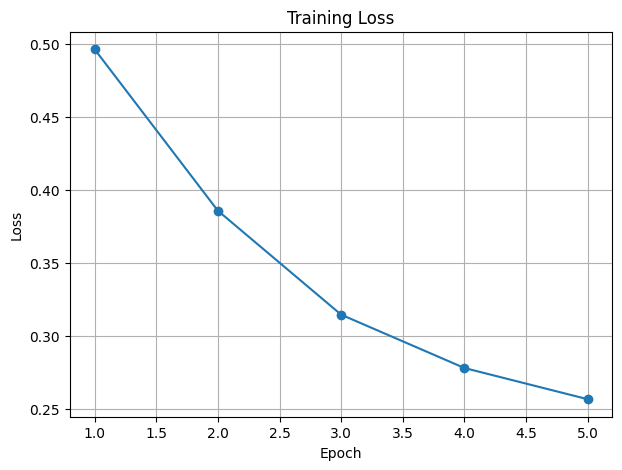

In [60]:
# Loss Graph
plt.figure(figsize=(7, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid()
plt.show()

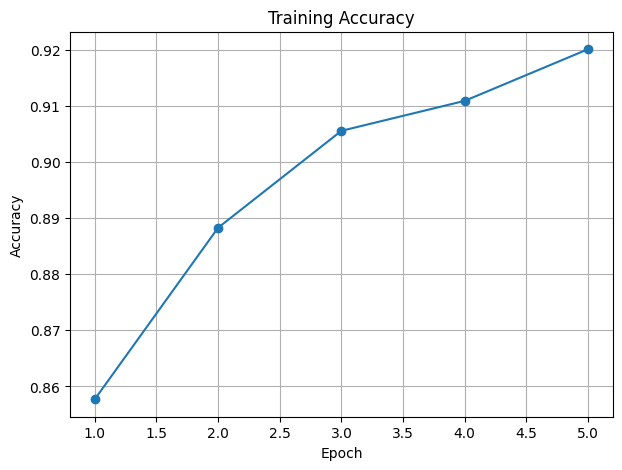

In [61]:
# Accuracy Graph
plt.figure(figsize=(7, 5))
plt.plot(range(1, EPOCHS + 1), train_accuracies, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.grid()
plt.show()

In [62]:
print("Hello")

Hello


In [63]:
import os

print(os.listdir())

['.config', 'spam_sms.csv', 'archive (2).zip', 'models', 'archive.zip', 'dataset.csv', 'sample_data']


In [64]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2) (1).zip


In [66]:
import pandas as pd

df = pd.read_csv("dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Shape: (22000, 2)
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
